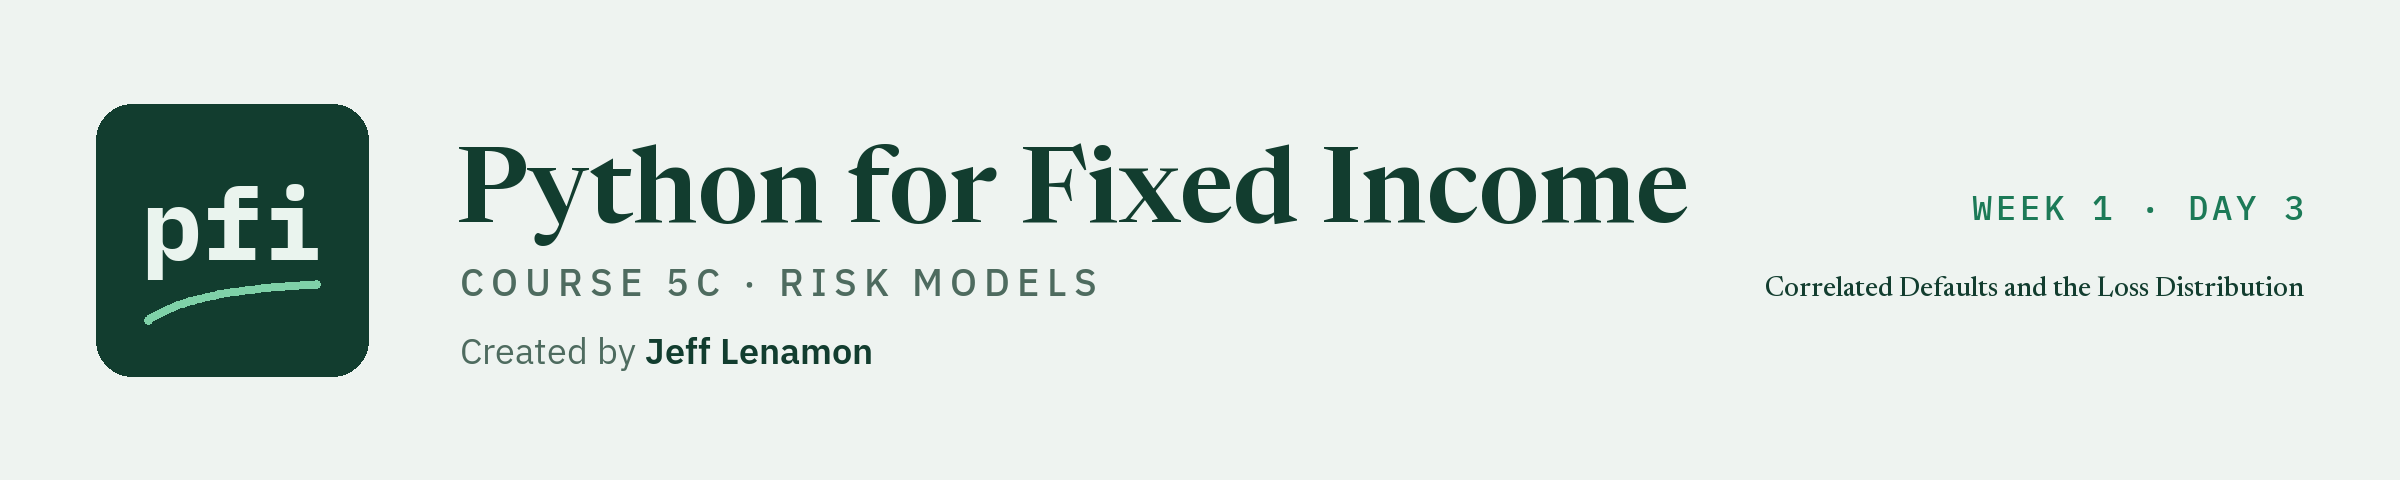

# Correlated Defaults and the Loss Distribution

Week 1, Day 3. Default rates from the synthetic cohort, defaults that move together through one common factor, the Vasicek formula, and the loss distribution of the book.

**Data:** `holdings.csv`, the course's book of 200 bonds as of 2026-09-30, with `ratings.csv` for the rating scale: **synthetic**, invented issuers and CUSIPs, no real company.

**Data:** `course5c_cohort.csv`, 4,000 invented firms followed year by year over 20 study years to default, exit, or the end: **synthetic**, ids only, no calendar years, and no agency default statistic.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course5c_risk_models/week1/day3/03_correlated_defaults_and_the_loss_distribution.ipynb)

Day 2's losses came from moves of the curve and of spreads. Today's come from defaults. A bond that defaults loses most of its value at once, and the question a desk asks is how many bonds can default in the same year. Day 1 counted defaults among independent bonds and found that a year with many defaults is very rare. Real defaults are not independent: in a bad year many issuers struggle at once. Today puts that into a model and reads the loss distribution of the book.

* **The default rates are synthetic.** They are counted from `course5c_cohort.csv`, 4,000 invented firms followed over study years, not calendar years. No agency default study, no real issuer's default probability, and no real rating's default rate appears.
* **Two inputs are chosen for the lesson.** The asset correlation of 0.20 and a loss given default drawn from a beta distribution with mean 60 percent are round inputs, said so where they are set.
* **Names.** The model's output is "the model's default probability for that rating", "a simulated loss", and "credit VaR". It is never a forecast of defaults, a rating view, or a statement about any real firm.

Today you will:

1. Count default rates by rating in the cohort's development years, meet the low-default problem, and fill it with a pooled logistic fit.
2. See that defaults cluster by year, more than independence allows.
3. Simulate defaults that move together through one common factor (`one_factor_defaults`), and sweep the correlation.
4. Check the simulation against the Vasicek formula (`vasicek_quantile`).
5. Simulate the book's credit loss (`loss_distribution`), read its VaR and expected shortfall, and find where the tail losses sit.
6. Correlate two factors with a Cholesky factor, and see the error a matrix that is not a correlation matrix raises.

Q. Set up today's work folder: the thread settings, the seed, the book, the cohort, and the modules.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course5c_risk_models/requirements.txt
NEEDED = {
    "arch": "arch==8.0.0",
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

18 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, scipy, statsmodels, or scikit-learn is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("statsmodels", "statsmodels"), ("scipy", "scipy"), ("sklearn", "scikit-learn"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course5c_risk_models/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scipy": "1.18.1", "statsmodels": "0.15.0", "scikit-learn": "1.9.1", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5c_03_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["holdings.csv", "ratings.csv", "course5c_cohort.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, scikit-learn 1.9.1, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5c_03_nb648h7n, in your temp folder
Data files from the data folder of the course repo: holdings.csv, ratings.csv, course5c_cohort.csv
SEED = 42


Q. Write `mlkit.py`, Course 4's complete module, unchanged. `riskkit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `riskkit.py` and `test_riskkit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile riskkit.py
"""riskkit: risk models for a bond desk, built day by day in Course 5C.

Conventions, stated once:
- Money is in US$. Rate and spread moves are in bp. A default probability is a fraction a year: 0.02 is 2 percent.
- A loss is a positive number of US$. P&L is positive for a gain.
- Every random draw comes from a numpy Generator the caller passes in as rng. Nothing here seeds a generator or
  uses the legacy np.random functions, so one seed at the top of a notebook decides every draw.
- The inputs are the course's synthetic book, its synthetic cohort, or past data. Nothing here describes a real
  security or a real issuer.
"""
import math

import numpy as np
from scipy.stats import norm

import mlkit  # noqa: F401  (the past-only checks, used from day 5)


def mc_mean(draws) -> tuple[float, float]:
    """The Monte Carlo estimate of a mean, and its standard error.

    Input: draws, a 1-D array of independent trial outcomes: at least 2, none of them NaN.
    Output: (mean, standard error). The standard error is the sample standard deviation (ddof=1) over the
    square root of the number of draws: how far the mean of this many draws typically lands from the true mean.
    Raises ValueError for fewer than 2 draws, more than one dimension, or a NaN.
    """
    values = np.asarray(draws, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("draws must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("draws hold a NaN")
    return float(values.mean()), float(values.std(ddof=1) / math.sqrt(len(values)))


def trials_needed(sd: float, half_width: float, confidence: float = 0.95) -> int:
    """How many independent trials put a Monte Carlo mean within half_width of the true mean, at this confidence.

    n = ceil((z * sd / half_width) ** 2), with z the two-sided normal quantile (1.96 at 0.95).
    Inputs: sd, the standard deviation of one trial, and half_width, in the same unit, both above 0; confidence
    strictly between 0 and 1.
    Output: the number of trials, a whole number.
    Raises ValueError for an sd or half_width that is not above 0, or a confidence outside (0, 1).
    """
    if sd <= 0 or half_width <= 0:
        raise ValueError("sd and half_width must be above 0")
    if not 0 < confidence < 1:
        raise ValueError("confidence must be between 0 and 1")
    z = norm.ppf(0.5 + confidence / 2)
    return math.ceil((z * sd / half_width) ** 2)


def antithetic_normals(rng: np.random.Generator, n: int) -> np.ndarray:
    """n standard normal draws in antithetic pairs: n // 2 draws z, then their mirror images -z.

    Inputs: rng, a numpy Generator; n, a positive even number.
    Output: an array of n draws. Draw i and draw i + n // 2 are a pair (z and -z), so the draws' mean is 0 exactly.
    A pair is not two independent draws: average each pair before computing a standard error.
    Raises ValueError for an n that is odd or not above 0.
    """
    if n <= 0 or n % 2:
        raise ValueError("n must be a positive even number")
    half = rng.standard_normal(n // 2)
    return np.concatenate([half, -half])


import pandas as pd  # dated tables: the book's P&L by day
from scipy.stats import chi2  # the chi-squared distribution of Kupiec's test


def historical_pnl(book, rate_moves, spread_moves):
    """The book's P&L on each past day, had that day's rate and spread moves happened to today's book.

    For each bond and day: the rate move is the Treasury change at the bond's years to maturity, read off the curve
    by straight-line interpolation between the two nearest tenors (the first or last tenor beyond the ends); the
    spread move is the bond's OAS times the relative change in its spread index (the DTS approach). The P&L is
    minus market value x (duration x rate move + spread duration x spread move) / 10,000. First order only: no
    convexity, no carry, no roll down the curve.
    Inputs:
    - book: a DataFrame with one row per bond and the columns market_value (US$), duration, spread_duration, oas
      (bp), years_to_maturity, and spread_index (the name of a column of spread_moves).
    - rate_moves: a DataFrame of daily Treasury changes in bp, one row per date, one column per tenor in years.
    - spread_moves: a DataFrame of daily relative changes of each spread index (0.01 is 1 percent wider), on the
      same dates as rate_moves.
    Output: a DataFrame on those dates with the columns rates, spreads, and total, in US$.
    Raises ValueError for a missing book column, an unknown spread index, dates that differ, or a NaN in the moves.
    """
    needed = ["market_value", "duration", "spread_duration", "oas", "years_to_maturity", "spread_index"]
    missing = [name for name in needed if name not in book.columns]
    if missing:
        raise ValueError(f"book lacks the columns {missing}")
    unknown = sorted(set(book["spread_index"]) - set(spread_moves.columns))
    if unknown:
        raise ValueError(f"spread_moves has no column for the spread indexes {unknown}")
    if not rate_moves.index.equals(spread_moves.index):
        raise ValueError("rate_moves and spread_moves must be on the same dates")
    if rate_moves.isna().any().any() or spread_moves[list(set(book["spread_index"]))].isna().any().any():
        raise ValueError("the moves hold a NaN")
    tenors = np.asarray(rate_moves.columns, dtype=float)
    # interpolation is linear in the curve's values, so each bond's weight on each tenor is the curve 0 everywhere
    # but 1 at that tenor, read at the bond's maturity
    weights = np.column_stack([np.interp(book["years_to_maturity"], tenors, np.eye(len(tenors))[j])
                               for j in range(len(tenors))])
    bond_rate_moves = rate_moves.to_numpy() @ weights.T
    bond_spread_moves = spread_moves[book["spread_index"]].to_numpy() * book["oas"].to_numpy()
    rates = -(bond_rate_moves * (book["duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    spreads = -(bond_spread_moves * (book["spread_duration"] * book["market_value"]).to_numpy()).sum(axis=1) / 10_000
    return pd.DataFrame({"rates": rates, "spreads": spreads, "total": rates + spreads}, index=rate_moves.index)


def var_es(pnl, level: float = 0.99) -> tuple[float, float]:
    """The VaR and the expected shortfall of a sample of P&L, both as positive US$ losses.

    VaR at level (for example 0.99) is minus the (1 - level) quantile of the P&L, with linear interpolation between
    the two nearest values: Excel's PERCENTILE.INC. Expected shortfall is minus the mean P&L on the days at or below
    that quantile: the average loss on the days the loss is at least the VaR, so it is never below the VaR.
    Inputs: pnl, a 1-D array of at least 2 values in US$, a gain positive, none of them NaN; level strictly between
    0.5 and 1.
    Output: (VaR, expected shortfall), in US$.
    Raises ValueError for fewer than 2 values, more than one dimension, a NaN, or a level outside (0.5, 1).
    """
    values = np.asarray(pnl, dtype=float)
    if values.ndim != 1 or len(values) < 2:
        raise ValueError("pnl must be a 1-D array of at least 2 values")
    if np.isnan(values).any():
        raise ValueError("pnl holds a NaN")
    if not 0.5 < level < 1:
        raise ValueError("level must be between 0.5 and 1")
    cutoff = float(np.quantile(values, 1 - level))
    return -cutoff, -float(values[values <= cutoff].mean())


def kupiec_pof(exceptions: int, n: int, level: float) -> tuple[float, float]:
    """Kupiec's proportion-of-failures test: is the count of VaR exceptions in line with the VaR's level?

    Under a correct VaR each of n days is an exception with chance p = 1 - level, independently. The statistic is
    the likelihood ratio LR = -2 ln[(1 - p)^(n - x) p^x] + 2 ln[(1 - x/n)^(n - x) (x/n)^x] for x exceptions, which
    is close to a chi-squared with 1 degree of freedom when the VaR is right.
    Inputs: exceptions, a whole number from 0 to n; n, the number of days tested, above 0; level strictly between
    0 and 1.
    Output: (LR, p-value). A small p-value says the count is hard to square with the level: too many exceptions,
    or too few.
    Raises ValueError for a count outside 0 to n, an n that is not above 0, or a level outside (0, 1).
    """
    if n <= 0 or not 0 <= exceptions <= n:
        raise ValueError("exceptions must be between 0 and n, and n above 0")
    if not 0 < level < 1:
        raise ValueError("level must be between 0 and 1")
    p, x = 1 - level, exceptions
    observed = x / n

    def log_likelihood(q: float) -> float:
        # x ln q + (n - x) ln(1 - q), with 0 ln 0 taken as 0
        return (x * math.log(q) if x else 0.0) + ((n - x) * math.log(1 - q) if n - x else 0.0)

    lr = max(0.0, -2 * (log_likelihood(p) - log_likelihood(observed)))
    return lr, float(chi2.sf(lr, 1))

Writing riskkit.py


In [5]:
%%writefile test_riskkit.py
"""Tests for riskkit.py. Small seeded arrays only; no data file is read."""
import math

import numpy as np
import pytest

import riskkit


def test_mc_mean_hand():
    # mean 2.5; sample standard deviation sqrt(5/3); standard error that over sqrt(4)
    mean, se = riskkit.mc_mean([1.0, 2.0, 3.0, 4.0])
    assert mean == 2.5
    assert se == pytest.approx(math.sqrt(5 / 3) / 2, rel=1e-12)


def test_mc_mean_refuses():
    with pytest.raises(ValueError, match="at least 2"):
        riskkit.mc_mean([1.0])
    with pytest.raises(ValueError, match="NaN"):
        riskkit.mc_mean([1.0, float("nan"), 3.0])


def test_mc_mean_covers_a_known_mean():
    # 2 percent default, US$600,000 lost: the true mean is US$12,000; 40,000 draws land within 4 standard errors
    rng = np.random.default_rng(42)
    losses = np.where(rng.random(40_000) < 0.02, 600_000.0, 0.0)
    mean, se = riskkit.mc_mean(losses)
    assert abs(mean - 12_000.0) < 4 * se


def test_trials_needed_hand():
    # z at 95 percent is 1.959964; (1.959964 * 10 / 1) ** 2 = 384.15, so 385 trials
    assert riskkit.trials_needed(10.0, 1.0) == 385
    # halving the half-width takes four times the trials, give or take the rounding up
    assert riskkit.trials_needed(10.0, 0.5) == 1_537
    with pytest.raises(ValueError, match="above 0"):
        riskkit.trials_needed(10.0, 0.0)
    with pytest.raises(ValueError, match="between 0 and 1"):
        riskkit.trials_needed(10.0, 1.0, confidence=1.0)


def test_antithetic_normals_pairs():
    draws = riskkit.antithetic_normals(np.random.default_rng(42), 10)
    assert len(draws) == 10
    assert np.array_equal(draws[5:], -draws[:5])
    assert draws.mean() == 0.0
    with pytest.raises(ValueError, match="even"):
        riskkit.antithetic_normals(np.random.default_rng(42), 7)


def test_antithetic_normals_same_seed_same_draws():
    first = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    second = riskkit.antithetic_normals(np.random.default_rng(7), 1_000)
    assert np.array_equal(first, second)


import pandas as pd


def _one_bond(years):
    return pd.DataFrame({"market_value": [1_000_000.0], "duration": [5.0], "spread_duration": [5.0], "oas": [100.0],
                         "years_to_maturity": [years], "spread_index": ["ig"]})


def test_historical_pnl_hand():
    # 4 years sits halfway between the 3 and 5 year tenors: a 15 bp move, and 10 percent of 100 bp is 10 bp
    dates = pd.to_datetime(["2020-01-02"])
    rates = pd.DataFrame({3.0: [10.0], 5.0: [20.0]}, index=dates)
    spreads = pd.DataFrame({"ig": [0.10]}, index=dates)
    pnl = riskkit.historical_pnl(_one_bond(4.0), rates, spreads)
    assert pnl.loc[dates[0], "rates"] == pytest.approx(-7_500.0, rel=1e-12)
    assert pnl.loc[dates[0], "spreads"] == pytest.approx(-5_000.0, rel=1e-12)
    assert pnl.loc[dates[0], "total"] == pytest.approx(-12_500.0, rel=1e-12)
    # beyond the last tenor the last tenor's move is used
    assert riskkit.historical_pnl(_one_bond(8.0), rates, spreads).loc[dates[0], "rates"] == pytest.approx(-10_000.0)


def test_historical_pnl_refuses():
    dates = pd.to_datetime(["2020-01-02", "2020-01-03"])
    rates = pd.DataFrame({3.0: [10.0, 1.0], 5.0: [20.0, 2.0]}, index=dates)
    with pytest.raises(ValueError, match="same dates"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"ig": [0.1]}, index=dates[:1]))
    with pytest.raises(ValueError, match="no column"):
        riskkit.historical_pnl(_one_bond(4.0), rates, pd.DataFrame({"hy": [0.1, 0.2]}, index=dates))
    with pytest.raises(ValueError, match="NaN"):
        riskkit.historical_pnl(_one_bond(4.0), rates.where(rates > 1), pd.DataFrame({"ig": [0.1, 0.2]}, index=dates))


def test_var_es_hand():
    # losses of 1 to 100: the 5 percent quantile of the P&L sits 4.95 of the way from -100 to -99, so VaR 95.05;
    # the days at or below it lose 100, 99, 98, 97, and 96, an average of 98
    var, es = riskkit.var_es(-np.arange(1.0, 101.0), 0.95)
    assert var == pytest.approx(95.05, rel=1e-12)
    assert es == pytest.approx(98.0, rel=1e-12)


def test_var_es_shortfall_at_least_var():
    pnl = np.random.default_rng(42).standard_t(4, 5_000)
    for level in (0.95, 0.99):
        var, es = riskkit.var_es(pnl, level)
        assert es >= var > 0


def test_var_es_refuses():
    with pytest.raises(ValueError, match="NaN"):
        riskkit.var_es([1.0, float("nan"), -2.0])
    with pytest.raises(ValueError, match="between 0.5 and 1"):
        riskkit.var_es([1.0, -2.0, 3.0], 0.01)


def test_kupiec_pof_hand():
    # exactly the expected count: the statistic is 0 and the p-value 1
    assert riskkit.kupiec_pof(10, 1_000, 0.99) == pytest.approx((0.0, 1.0))
    # 5 exceptions in 250 days at 99 percent, against the formula written out
    x, n, p = 5, 250, 0.01
    lr = -2 * ((n - x) * math.log(1 - p) + x * math.log(p) - (n - x) * math.log(1 - x / n) - x * math.log(x / n))
    assert riskkit.kupiec_pof(x, n, 0.99)[0] == pytest.approx(lr, rel=1e-12)
    # no exception at all is too few for a long sample
    assert riskkit.kupiec_pof(0, 2_000, 0.99)[1] < 0.01


def test_kupiec_pof_refuses():
    with pytest.raises(ValueError, match="between 0 and n"):
        riskkit.kupiec_pof(11, 10, 0.99)

Writing test_riskkit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import mlkit
import riskkit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(riskkit)

# the functions defined in riskkit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(riskkit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "riskkit" and not name.startswith("_")]
print(f"riskkit functions: {functions}")

riskkit functions: ['mc_mean', 'trials_needed', 'antithetic_normals', 'historical_pnl', 'var_es', 'kupiec_pof']


Q. Write `plotkit.py`, the series' chart and table helpers from Course 4 (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt

if str(work) not in sys.path:
    sys.path.insert(0, str(work))
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


* The setup cell is the one from days 1 and 2. It writes `riskkit.py` and `test_riskkit.py` as day 2 left them.

## 3.1 Default Rates from the Cohort

**How it works.** A default rate is counted, not assumed: the number of defaults in a group divided by the number of firm-years at risk. A firm-year is one firm watched for one year; a firm watched for 6 years before it left the study counts 6. The cohort file has one row per firm-year, with the firm's rating at the start of that year and a 1 in the `default` column in the year it defaulted. The settings are the years counted and how firms are grouped. What comes out is a default rate a year for each group, with the number of firm-years behind it.

Q. Load the cohort and fix the development years before counting anything.

In [9]:
# the synthetic cohort: invented firms with ids only, followed in study years, not calendar years
cohort = pd.read_csv("course5c_cohort.csv")
ratings = pd.read_csv("ratings.csv").set_index("rating")

# the development study years are fixed before any default rate is counted; years 15 to 20 stay closed until the capstone
DEVELOPMENT_END = 14
development = cohort[cohort["study_year"] <= DEVELOPMENT_END].copy()
development["bucket"] = development["rating"].map(ratings["bucket"])
print(f"{cohort['firm_id'].nunique():,} invented firms; development years 1 to {DEVELOPMENT_END}: "
      f"{len(development):,} firm-years, {int(development['default'].sum())} defaults")
print(f"held-out firm-years left closed: {int((cohort['study_year'] > DEVELOPMENT_END).sum()):,}")

4,000 invented firms; development years 1 to 14: 18,503 firm-years, 345 defaults
held-out firm-years left closed: 11,112


* 18,503 firm-years and 345 defaults in study years 1 to 14. The 11,112 firm-years of study years 15 to 20 are counted and left alone: day 9 and the capstone use them.

Q. What is the default rate of each rating bucket?

In [10]:
# firm-years and defaults by rating bucket: a firm-year is one firm at risk for one study year
BUCKETS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]
rates = (development.groupby("bucket")
         .agg(firm_years=("default", "size"), defaults=("default", "sum"))
         .reindex(BUCKETS))
rates["default rate (percent a year)"] = 100 * rates["defaults"] / rates["firm_years"]
rates.columns = ["firm-years", "defaults", "default rate (percent a year)"]
rates.index.name = "bucket"
print(rates.round(3).to_string())

        firm-years  defaults  default rate (percent a year)
bucket                                                     
AAA            168         0                          0.000
AA            1274         0                          0.000
A             3014         3                          0.100
BBB           4897        10                          0.204
BB            5142        64                          1.245
B             3207       149                          4.646
CCC            801       119                         14.856


In [11]:
plotkit.styled(rates, [], "Default rates of the synthetic cohort by rating bucket, development study years 1 to 14", fmt="{:,.3f}")

,firm-years,defaults,default rate (percent a year)
bucket,,,
AAA,168,0,0.000
AA,"1,274",0,0.000
A,"3,014",3,0.100
BBB,"4,897",10,0.204
BB,"5,142",64,1.245
B,"3,207",149,4.646
CCC,801,119,14.856


* The rate climbs with every bucket, from none in AAA and AA to 14.9 percent a year in CCC.
* **The low-default problem.** AA has 1,274 firm-years and no default; AAA has 168 and none. A count of zero is not a chance of zero: it says the chance is small, not how small. Even A, with 3 defaults, rests on very few events. A model that gives AAA a default probability of exactly 0 would put no capital and no loss on those bonds at all.

Q. Fill the gap: fit one logistic regression of default on the rating score, using every firm-year at once.

In [12]:
import statsmodels.api as sm

# one pooled logistic regression of default on the rating score: every notch's firm-years shape every notch's rate
X = sm.add_constant(development[["rating_score"]].astype(float))
logit = sm.Logit(development["default"], X).fit(disp=0)
print(pd.DataFrame({"coefficient": logit.params, "standard error": logit.bse}).round(4).to_string())

# observed and fitted default rates for every notch of the scale, in percent a year
notches = ratings[["score", "bucket"]].copy()
observed = development.groupby("rating")["default"].agg(["size", "sum"])
notches["firm-years"] = observed["size"].reindex(notches.index).fillna(0).astype(int)
notches["defaults"] = observed["sum"].reindex(notches.index).fillna(0).astype(int)
notches["observed (percent a year)"] = 100 * notches["defaults"] / notches["firm-years"]
notch_X = sm.add_constant(notches[["score"]].rename(columns={"score": "rating_score"}).astype(float))
notches["fitted (percent a year)"] = 100 * logit.predict(notch_X)
print(notches.loc[["AAA", "AA", "A", "BBB", "BB", "B", "CCC"], ["observed (percent a year)", "fitted (percent a year)"]].round(4).to_string())

              coefficient  standard error
const            -10.4489          0.3564
rating_score       0.4967          0.0234
        observed (percent a year)  fitted (percent a year)
rating                                                    
AAA                        0.0000                   0.0048
AA                         0.0000                   0.0129
A                          0.0000                   0.0571
BBB                        0.1210                   0.2527
BB                         1.2921                   1.1119
B                          5.0657                   4.7532
CCC                       17.4603                  18.1324


* One coefficient for the whole scale: each notch multiplies the odds of default by e to the 0.497, 1.64 times, with a standard error of 0.023. The fitted rate for AA is 0.0129 percent a year and for AAA 0.0048 percent: small and above zero, borrowed from the slope the lower notches show.
* The fit's assumption is that the log-odds of default rise in a straight line with the score. The lower notches, where defaults are plenty, can check that line; the top notches cannot, and their rate is the line's word, not the data's.

Q. Draw each notch's counted rate beside the fitted one.

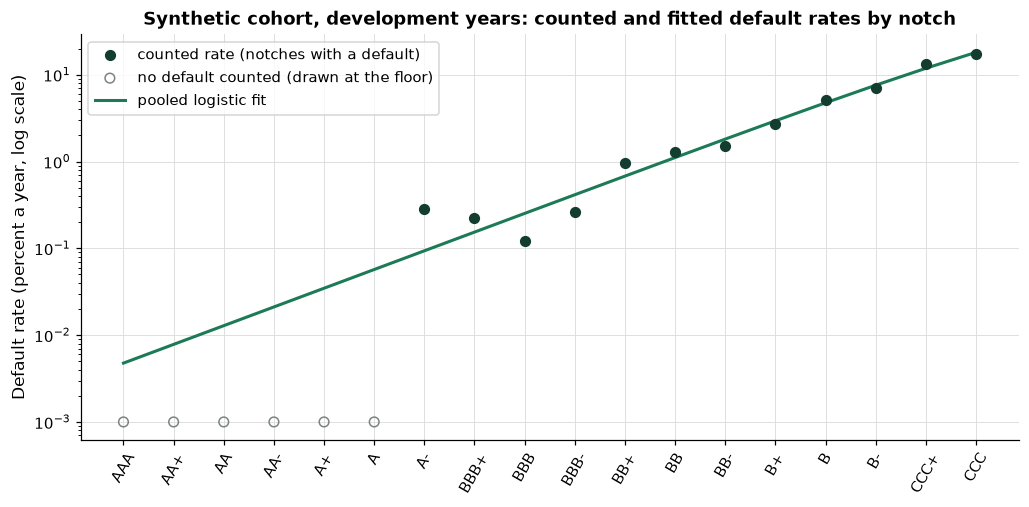

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.8))
counted = notches[notches["defaults"] > 0]
ax.scatter(counted["score"], counted["observed (percent a year)"], color=plotkit.GREEN_DARK, s=40, zorder=3,
           label="counted rate (notches with a default)")
none = notches[(notches["defaults"] == 0) & (notches["firm-years"] > 0)]
floor = 0.001
ax.scatter(none["score"], np.full(len(none), floor), facecolors="none", edgecolors=plotkit.GREY, s=40, zorder=3,
           label="no default counted (drawn at the floor)")
ax.plot(notches["score"], notches["fitted (percent a year)"], color=plotkit.GREEN, linewidth=2, label="pooled logistic fit")
ax.set_yscale("log")
ax.set_xticks(notches["score"])
ax.set_xticklabels(notches.index, rotation=60)
ax.set_ylabel("Default rate (percent a year, log scale)")
ax.set_title("Synthetic cohort, development years: counted and fitted default rates by notch")
ax.legend(loc="upper left")
plt.show()

* How to read it: the y axis is logarithmic, so the straight line is the logistic fit's constant multiple per notch. Where defaults are many, from BBB down, the dark points sit near the line. Above that, the hollow points are notches with no default at all, drawn at a floor because a log scale cannot show zero; the line runs on through them. That run is the whole of what the data say about the top of the scale.

Q. Give every bond of the book the fitted default probability of its rating, and compute the book's exact expected loss.

In [14]:
# the book of 2026-09-30: every bond takes the fitted default probability of its rating notch
book = pd.read_csv("holdings.csv")
book["rating_score"] = book["rating"].map(ratings["score"]).astype(float)
book["pd"] = logit.predict(sm.add_constant(book[["rating_score"]]))
print(f"{len(book)} bonds, market value US${book['market_value'].sum():,.0f}")
print(f"default probability a year: {book['pd'].min():.4%} to {book['pd'].max():.2%}, average {book['pd'].mean():.2%}")

# the exact expected loss of one year, with a loss given default of 60 percent on average
LGD_MEAN = 0.60
expected_loss = float((book["pd"] * LGD_MEAN * book["market_value"]).sum())
print(f"expected loss of one year: US${expected_loss:,.0f}")

200 bonds, market value US$490,819,215
default probability a year: 0.0048% to 18.13%, average 1.17%
expected loss of one year: US$3,482,412


* The book's expected loss over one year is US$3.48m: the sum over bonds of the default probability, times 60 percent, times market value. That is the mean of the loss distribution, whatever the correlation. Correlation changes the tail, as sections 3.3 to 3.5 show.

## 3.2 Defaults Come in Clusters

**How it works.** If firms defaulted independently, each year's count of defaults would scatter around the fitted count like a coin-flip total: within about 1.96 binomial standard deviations in 95 percent of years. When many firms default in the same bad years, the counts scatter far more, and the variance of the yearly counts is several times the independent variance. The setting is the model whose fitted counts are the baseline. What comes out is a picture of the yearly counts against their independent band, and one ratio: about 1 for independent defaults, larger for clustered ones.

Q. Compare each study year's count of defaults with the band independent defaults would stay in.

In [15]:
# each study year's defaults against the count the fitted model gives if firms defaulted independently
fitted = logit.predict(X)
by_year = development.groupby("study_year").agg(firm_years=("default", "size"), defaults=("default", "sum"))
by_year["fitted defaults"] = fitted.groupby(development["study_year"]).sum()
# the binomial spread of a count of independent defaults, each with its own fitted probability
spread_independent = np.sqrt((fitted * (1 - fitted)).groupby(development["study_year"]).sum())
by_year["low (independent)"] = by_year["fitted defaults"] - 1.96 * spread_independent
by_year["high (independent)"] = by_year["fitted defaults"] + 1.96 * spread_independent
outside = int(((by_year["defaults"] < by_year["low (independent)"]) | (by_year["defaults"] > by_year["high (independent)"])).sum())
# how much more the yearly counts vary than independence allows: about 1 if independent
dispersion = float((((by_year["defaults"] - by_year["fitted defaults"]) / spread_independent) ** 2).mean())
print(f"years outside the independent 95 percent band: {outside} of {len(by_year)}")
print(f"variance of the yearly counts over the independent variance: {dispersion:.2f}")

years outside the independent 95 percent band: 3 of 14
variance of the yearly counts over the independent variance: 2.17


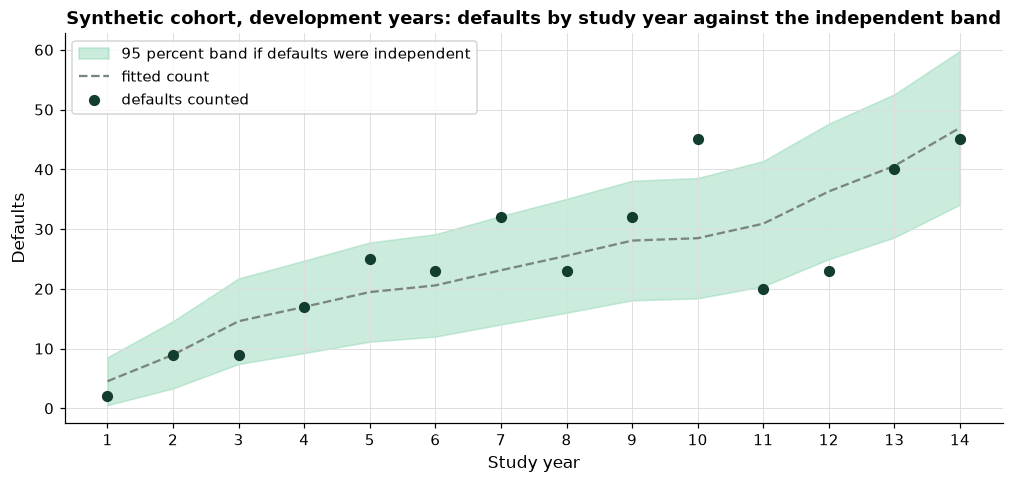

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.6))
years = by_year.index
ax.fill_between(years, by_year["low (independent)"], by_year["high (independent)"], color=plotkit.GREEN_LIGHT, alpha=0.4,
                label="95 percent band if defaults were independent")
ax.plot(years, by_year["fitted defaults"], color=plotkit.GREY, linestyle="--", label="fitted count")
ax.scatter(years, by_year["defaults"], color=plotkit.GREEN_DARK, s=40, zorder=3, label="defaults counted")
ax.set_xticks(years)
ax.set_xlabel("Study year")
ax.set_ylabel("Defaults")
ax.set_title("Synthetic cohort, development years: defaults by study year against the independent band")
ax.legend(loc="upper left")
plt.show()

* How to read it: the band grows with the cohort, because more firms are at risk each year. 3 of the 14 years fall outside it, against about 1 in 20 if defaults were independent, and the yearly counts vary 2.2 times as much as independence allows.
* The cohort was made with a common factor in each study year, shared by every firm (its generator and coefficients are in the repo's `DATA.md`), so this is the planted clustering showing through. The one-factor model of section 3.3 is the simplest way to put it into a simulation.

## 3.3 The One-Factor Model

**How it works.** Give each bond an asset value: sqrt(rho) times a common factor Z, shared by every bond in a scenario, plus sqrt(1 - rho) times a factor of its own. Both are standard normal, so the asset value is too. The bond defaults when its asset value falls below a threshold, the normal quantile of its default probability, so each bond still defaults with exactly its own probability. In a scenario where Z is low, every bond is closer to its threshold at once: that is a bad year. The setting is rho, the **asset correlation**: 0 gives independent defaults, larger values give more years with many defaults and more with none. What comes out is a scenarios-by-bonds table of defaults.

Q. Add `one_factor_defaults` to `riskkit.py`. Read the docstring first.

In [17]:
%%writefile -a riskkit.py


def one_factor_defaults(pd, rho: float, n_sims: int, rng: np.random.Generator) -> np.ndarray:
    """Simulated defaults of a group of bonds whose defaults move together through one common factor.

    In each scenario every bond's asset value is sqrt(rho) x Z + sqrt(1 - rho) x e, with Z one standard normal draw
    shared by every bond (the state of the economy) and e a standard normal draw of the bond's own. A bond defaults
    when its asset value is below the normal quantile of its default probability, so each bond still defaults with
    exactly its own probability, and rho sets how often they default together.
    Inputs: pd, a number or a 1-D array of annual default probabilities, one per bond, each strictly between 0 and
    1; rho, the asset correlation, from 0 up to (not including) 1; n_sims, the number of scenarios, above 0; rng, a
    numpy Generator.
    Output: a boolean array of shape (n_sims, number of bonds): True where that bond defaulted in that scenario.
    Raises ValueError for a pd outside (0, 1), a rho outside [0, 1), or an n_sims that is not above 0.
    """
    probabilities = np.atleast_1d(np.asarray(pd, dtype=float))
    if probabilities.ndim != 1 or not ((probabilities > 0) & (probabilities < 1)).all():
        raise ValueError("pd must be a number or a 1-D array, each strictly between 0 and 1")
    if not 0 <= rho < 1:
        raise ValueError("rho must be from 0 up to 1")
    if n_sims <= 0:
        raise ValueError("n_sims must be above 0")
    common = rng.standard_normal((n_sims, 1))
    own = rng.standard_normal((n_sims, len(probabilities)))
    assets = math.sqrt(rho) * common + math.sqrt(1 - rho) * own
    return assets < norm.ppf(probabilities)

Appending to riskkit.py


* The common draw has shape (scenarios, 1): one column, which numpy stretches across every bond. That one shape is the whole difference between correlated and independent defaults (Exercise 5).
* The threshold is `norm.ppf(pd)`: a standard normal value falls below it with chance pd, whatever rho is.

In [18]:
%%writefile -a test_riskkit.py


from scipy.stats import norm


def test_one_factor_defaults_shape_and_rate():
    defaults = riskkit.one_factor_defaults([0.02, 0.10], 0.3, 50_000, np.random.default_rng(42))
    assert defaults.shape == (50_000, 2) and defaults.dtype == bool
    # each bond still defaults with its own probability, whatever rho is
    assert defaults[:, 0].mean() == pytest.approx(0.02, abs=0.003)
    assert defaults[:, 1].mean() == pytest.approx(0.10, abs=0.006)


def test_one_factor_defaults_correlation_fattens_the_count():
    # 100 alike bonds: the mean count stays at 2, the chance of 10 or more grows with rho
    rng_a, rng_b = np.random.default_rng(42).spawn(2)
    independent = riskkit.one_factor_defaults(np.full(100, 0.02), 0.0, 20_000, rng_a).sum(axis=1)
    correlated = riskkit.one_factor_defaults(np.full(100, 0.02), 0.3, 20_000, rng_b).sum(axis=1)
    assert abs(independent.mean() - correlated.mean()) < 0.2
    assert (correlated >= 10).mean() > 10 * max((independent >= 10).mean(), 1e-4)


def test_one_factor_defaults_refuses():
    with pytest.raises(ValueError, match="strictly between 0 and 1"):
        riskkit.one_factor_defaults([0.02, 0.0], 0.2, 10, np.random.default_rng(42))
    with pytest.raises(ValueError, match="rho"):
        riskkit.one_factor_defaults(0.02, 1.0, 10, np.random.default_rng(42))

Appending to test_riskkit.py


In [19]:
importlib.reload(riskkit)
print(f"one_factor_defaults in riskkit: {hasattr(riskkit, 'one_factor_defaults')}")

one_factor_defaults in riskkit: True


In [20]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................                                                         [100%]
16 passed in 1.78s



* `16 passed`. The tests check the two promises: each bond defaults at its own rate, and correlation fattens the count without moving its mean.

Q. Draw the model for two bonds with a 5 percent default chance each: 2,000 scenarios at rho 0 and at rho 0.5.

In [21]:
from scipy.stats import norm

# two bonds, each with a 5 percent default chance, in 2,000 scenarios: rho 0 against rho 0.5
PAIR_PD = 0.05
threshold = norm.ppf(PAIR_PD)
pair_rows = []
pair_assets = {}
for rho, stream in zip([0.0, 0.5], np.random.default_rng(SEED).spawn(2)):
    common = stream.standard_normal((2_000, 1))
    own = stream.standard_normal((2_000, 2))
    assets = np.sqrt(rho) * common + np.sqrt(1 - rho) * own
    pair_assets[rho] = assets
    both = float(np.mean((assets < threshold).all(axis=1)))
    pair_rows.append({"rho": rho, "bond 1 defaults": float(np.mean(assets[:, 0] < threshold)),
                      "bond 2 defaults": float(np.mean(assets[:, 1] < threshold)), "both default": both,
                      "both, if independent": PAIR_PD ** 2})
pairs = pd.DataFrame(pair_rows).set_index("rho")
print(pairs.round(4).to_string())

     bond 1 defaults  bond 2 defaults  both default  both, if independent
rho                                                                      
0.0            0.054           0.0465         0.004                0.0025
0.5            0.047           0.0495         0.012                0.0025


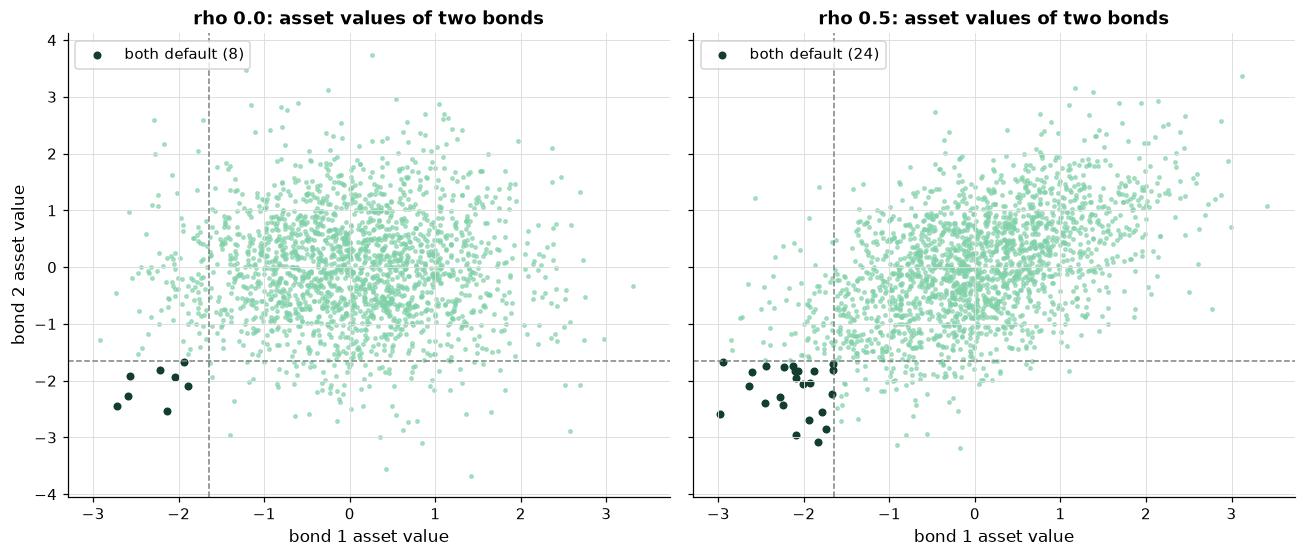

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)
for ax, rho in zip(axes, [0.0, 0.5]):
    assets = pair_assets[rho]
    both = (assets < threshold).all(axis=1)
    ax.scatter(assets[~both, 0], assets[~both, 1], s=5, color=plotkit.GREEN_LIGHT, alpha=0.6)
    ax.scatter(assets[both, 0], assets[both, 1], s=18, color=plotkit.GREEN_DARK, label=f"both default ({both.sum()})")
    ax.axvline(threshold, color=plotkit.GREY, linestyle="--", linewidth=1)
    ax.axhline(threshold, color=plotkit.GREY, linestyle="--", linewidth=1)
    ax.set_title(f"rho {rho}: asset values of two bonds")
    ax.set_xlabel("bond 1 asset value")
    ax.legend(loc="upper left")
axes[0].set_ylabel("bond 2 asset value")
fig.tight_layout()
plt.show()

* How to read it: each point is one scenario; the dashed lines are the default thresholds, so a point left of the vertical line is a default of bond 1 and a point below the horizontal one a default of bond 2. At rho 0 the cloud is round and both bonds default together in 0.40% of scenarios, near 5 percent times 5 percent, 0.25 percent, as 2,000 scenarios allow. At rho 0.5 the cloud leans along the diagonal and both default in 1.20%: each bond's own rate has not moved, but they now fail together.

Q. Sweep rho for 100 alike bonds at a 2 percent default chance. What happens to the count's mean, and to its tail?

In [23]:
# 100 alike bonds at a 2 percent default chance, 50,000 scenarios at each correlation, one stream each
RHOS = [0.0, 0.1, 0.2, 0.4]
counts = {rho: riskkit.one_factor_defaults(np.full(100, 0.02), rho, 50_000, stream).sum(axis=1)
          for rho, stream in zip(RHOS, np.random.default_rng(SEED).spawn(len(RHOS)))}
correlation_sweep = pd.DataFrame({
    "mean defaults": {rho: c.mean() for rho, c in counts.items()},
    "standard deviation": {rho: c.std() for rho, c in counts.items()},
    "99th percentile": {rho: np.quantile(c, 0.99) for rho, c in counts.items()},
    "chance of 10 or more": {rho: np.mean(c >= 10) for rho, c in counts.items()},
    "chance of none": {rho: np.mean(c == 0) for rho, c in counts.items()},
})
correlation_sweep.index.name = "rho"
print(correlation_sweep.round(4).to_string())

     mean defaults  standard deviation  99th percentile  chance of 10 or more  chance of none
rho                                                                                          
0.0         2.0070              1.3988              6.0                0.0000          0.1318
0.1         2.0027              2.1851             10.0                0.0117          0.2702
0.2         2.0079              3.0114             14.0                0.0310          0.3836
0.4         1.9965              4.6279             23.0                0.0543          0.5642


In [24]:
plotkit.styled(correlation_sweep, ["chance of 10 or more"], "100 alike bonds at a 2 percent default chance, 50,000 "
               "scenarios at each asset correlation", fmt="{:,.4f}")

,mean defaults,standard deviation,99th percentile,chance of 10 or more,chance of none
rho,,,,,
0,2.0070,1.3988,6.0000,0.0000,0.1318
0.1,2.0027,2.1851,10.0000,0.0117,0.2702
0.2,2.0079,3.0114,14.0000,0.0310,0.3836
0.4,1.9965,4.6279,23.0000,0.0543,0.5642


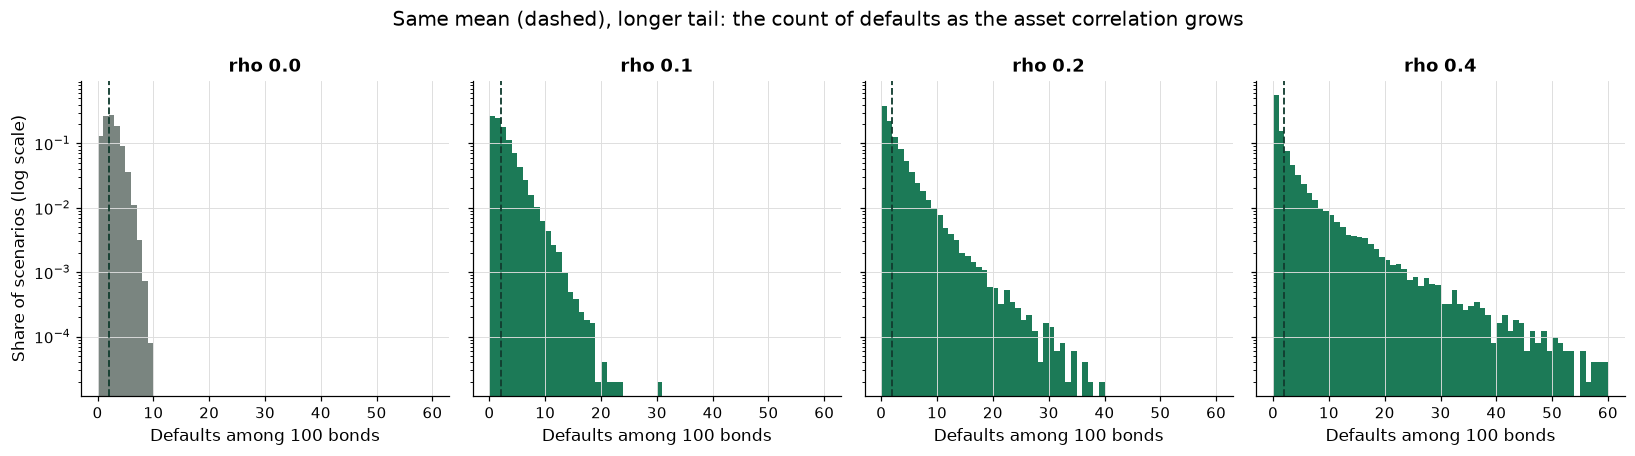

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
bins = np.arange(0, 61)
for ax, (rho, c) in zip(axes, counts.items()):
    ax.hist(c, bins=bins, color=plotkit.GREEN if rho else plotkit.GREY, density=True)
    ax.axvline(c.mean(), color=plotkit.GREEN_DARK, linestyle="--", linewidth=1.2)
    ax.set_yscale("log")
    ax.set_title(f"rho {rho}")
    ax.set_xlabel("Defaults among 100 bonds")
axes[0].set_ylabel("Share of scenarios (log scale)")
fig.suptitle("Same mean (dashed), longer tail: the count of defaults as the asset correlation grows")
fig.tight_layout()
plt.show()

* How to read it: every panel has the same dashed mean, 2 defaults. At rho 0 the count is binomial and never strays far: 10 or more defaults did not happen once in 50,000 scenarios. At rho 0.2 that happens in 3.10%, at 0.4 in 5.43%, and the 99th percentile climbs from 6 to 23 defaults.
* The other end moves too: a year with no default at all goes from 13.2% of scenarios at rho 0 to 56.4% at rho 0.4. Correlation does not add defaults; it moves them into the same years.

## 3.4 The Vasicek Formula

**How it works.** For a very large group of alike bonds, each bond's own factor averages out, and the share that defaults in a scenario depends on the common factor alone: N((N^-1(pd) - sqrt(rho) Z) / sqrt(1 - rho)), N the standard normal distribution. The share is high when Z is low, so the q quantile of the default rate is the same formula with Z at its own bad-side quantile: N((N^-1(pd) + sqrt(rho) N^-1(q)) / sqrt(1 - rho)). That is the **Vasicek formula**. Its settings are pd, rho, and q. What comes out is a default rate a group of that kind exceeds with chance 1 - q, with no simulation, exact only when the group is large and alike.

Q. Add `vasicek_quantile` to `riskkit.py`, with its tests.

In [26]:
%%writefile -a riskkit.py


def vasicek_quantile(pd: float, rho: float, q: float) -> float:
    """The default rate of a very large group of alike bonds that is not exceeded with probability q (Vasicek).

    N((N^-1(pd) + sqrt(rho) x N^-1(q)) / sqrt(1 - rho)), N the standard normal distribution: the one-factor model's
    default rate when the common factor sits at its own q quantile on the bad side. Exact only in the limit of
    many bonds, each with the same pd and rho.
    Inputs: pd, rho, and q, each strictly between 0 and 1.
    Output: a default rate between 0 and 1.
    Raises ValueError for any input outside (0, 1).
    """
    for name, value in (("pd", pd), ("rho", rho), ("q", q)):
        if not 0 < value < 1:
            raise ValueError(f"{name} must be strictly between 0 and 1")
    return float(norm.cdf((norm.ppf(pd) + math.sqrt(rho) * norm.ppf(q)) / math.sqrt(1 - rho)))

Appending to riskkit.py


In [27]:
%%writefile -a test_riskkit.py


def test_vasicek_quantile_hand():
    # at q = 0.5 the common factor sits at 0: N(N^-1(pd) / sqrt(1 - rho))
    assert riskkit.vasicek_quantile(0.02, 0.2, 0.5) == pytest.approx(norm.cdf(norm.ppf(0.02) / math.sqrt(0.8)), rel=1e-12)
    # a rho near 0 gives back pd at any q
    assert riskkit.vasicek_quantile(0.02, 1e-12, 0.999) == pytest.approx(0.02, rel=1e-4)
    with pytest.raises(ValueError, match="rho"):
        riskkit.vasicek_quantile(0.02, 0.0, 0.999)

Appending to test_riskkit.py


In [28]:
importlib.reload(riskkit)
print(f"vasicek_quantile in riskkit: {hasattr(riskkit, 'vasicek_quantile')}")

vasicek_quantile in riskkit: True


In [29]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.................                                                        [100%]
17 passed in 1.74s



* `17 passed`. The hand tests use two limits: at q = 0.5 the common factor sits at 0, and with rho near 0 the formula gives back pd.

Q. Check the formula: simulate 2,000 alike bonds at 2 percent and rho 0.2, and compare the default rate's quantiles.

In [30]:
# 2,000 alike bonds at 2 percent and rho 0.2: 20,000 scenarios, simulated 2,000 at a time to keep memory small
GROUP_PD, GROUP_RHO = 0.02, 0.2
rng = np.random.default_rng(SEED)
group_rates = np.concatenate([riskkit.one_factor_defaults(np.full(2_000, GROUP_PD), GROUP_RHO, 2_000, rng).mean(axis=1)
                              for _ in range(10)])
levels = [0.5, 0.9, 0.99, 0.999]
vasicek_check = pd.DataFrame({
    "simulated (percent)": [100 * np.quantile(group_rates, q) for q in levels],
    "Vasicek (percent)": [100 * riskkit.vasicek_quantile(GROUP_PD, GROUP_RHO, q) for q in levels],
}, index=pd.Index(levels, name="q"))
vasicek_check["gap (percent)"] = vasicek_check["simulated (percent)"] - vasicek_check["Vasicek (percent)"]
print(vasicek_check.round(3).to_string())

       simulated (percent)  Vasicek (percent)  gap (percent)
q                                                           
0.500                1.100              1.083          0.017
0.900                4.950              4.892          0.058
0.990               13.400             12.861          0.540
0.999               22.101             22.631         -0.530


In [31]:
plotkit.styled(vasicek_check, [], "2,000 alike bonds at a 2 percent default chance and rho 0.2: simulated default rate "
               "quantiles against the Vasicek formula", fmt="{:,.3f}")

,simulated (percent),Vasicek (percent),gap (percent)
q,,,
0.5,1.100,1.083,0.017
0.9,4.950,4.892,0.058
0.99,13.400,12.861,0.540
0.999,22.101,22.631,-0.530


* The median default rate is 1.08 percent, below the 2 percent mean: in most scenarios the group does better than average, and a few bad ones pull the mean up. At q = 0.999 the formula gives 22.63 percent and the simulation 22.10 percent: the 20th worst of 20,000 scenarios, close to the formula and as noisy as 20 scenarios make it.

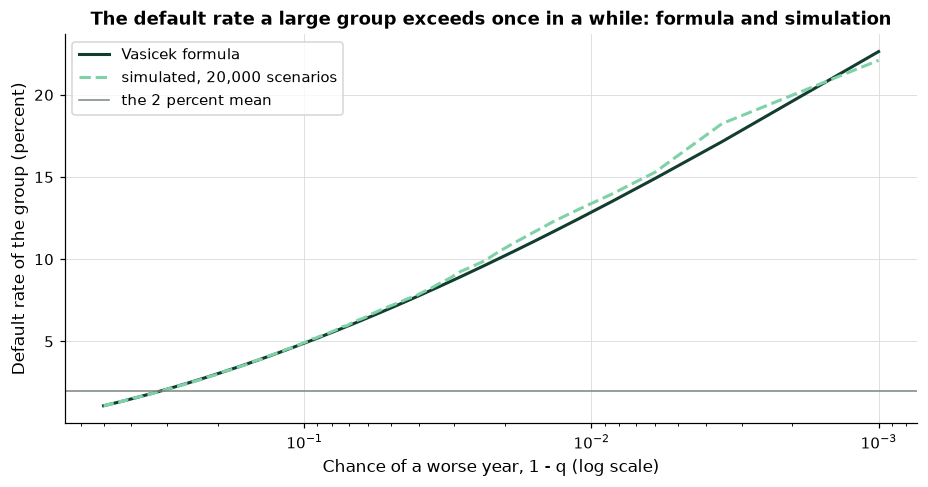

In [32]:
fig, ax = plt.subplots(figsize=(10, 4.6))
q_grid = np.linspace(0.5, 0.999, 200)
ax.plot(1 - q_grid, [100 * riskkit.vasicek_quantile(GROUP_PD, GROUP_RHO, q) for q in q_grid], color=plotkit.GREEN_DARK,
        linewidth=2, label="Vasicek formula")
ax.plot(1 - q_grid, 100 * np.quantile(group_rates, q_grid), color=plotkit.GREEN_LIGHT, linewidth=2, linestyle="--",
        label="simulated, 20,000 scenarios")
ax.axhline(100 * GROUP_PD, color=plotkit.GREY, linewidth=1, label="the 2 percent mean")
ax.set_xscale("log")
ax.invert_xaxis()
ax.set_xlabel("Chance of a worse year, 1 - q (log scale)")
ax.set_ylabel("Default rate of the group (percent)")
ax.set_title("The default rate a large group exceeds once in a while: formula and simulation")
ax.legend(loc="upper left")
plt.show()

* How to read it: from left to right the years get rarer, from one in two to one in a thousand. The simulated line follows the formula closely until the far right, where only a few scenarios are left and it wobbles. A once-in-a-thousand-years rate is more than ten times the average one: that gap is what correlation does.

## 3.5 The Book's Loss Distribution

**How it works.** Put the pieces together for the book. Each bond has its fitted default probability from section 3.1. In each scenario the one-factor model decides which bonds default, each defaulted bond loses its market value times a **loss given default** drawn from a beta distribution (day 1, section 1.4), and the scenario's loss is the sum. Thousands of scenarios make the **loss distribution**. Its mean is the expected loss; its high percentiles are **credit VaR** and their expected shortfall. The settings are rho, the LGD distribution, and the number of scenarios. What comes out is a loss in US$ for every scenario, and from them the tail.

Q. Add `loss_distribution` to `riskkit.py`, with its test.

In [33]:
%%writefile -a riskkit.py


def loss_distribution(book, defaults, lgd) -> np.ndarray:
    """The credit loss of the book in each simulated scenario, in US$.

    A defaulted bond loses its market value (its exposure at default) times its loss given default; a bond that did
    not default loses nothing.
    Inputs: book, a DataFrame with a market_value column (US$), one row per bond; defaults, a boolean array of shape
    (scenarios, bonds), as one_factor_defaults returns; lgd, the loss given default as a share between 0 and 1: a
    number, one per bond, or one per scenario and bond.
    Output: an array of one loss per scenario, in US$ (positive is a loss).
    Raises ValueError for defaults whose number of columns is not the number of bonds, or an lgd outside [0, 1].
    """
    hits = np.asarray(defaults, dtype=bool)
    exposure = book["market_value"].to_numpy(dtype=float)
    if hits.ndim != 2 or hits.shape[1] != len(exposure):
        raise ValueError("defaults must have one column per bond of the book")
    shares = np.asarray(lgd, dtype=float)
    if ((shares < 0) | (shares > 1)).any():
        raise ValueError("lgd must be between 0 and 1")
    return (hits * shares * exposure).sum(axis=1)

Appending to riskkit.py


In [34]:
%%writefile -a test_riskkit.py


def test_loss_distribution_hand():
    book = pd.DataFrame({"market_value": [100.0, 200.0, 300.0]})
    defaults = np.array([[True, False, True], [False, False, False]])
    # scenario 1 loses 60 percent of 100 and of 300; scenario 2 loses nothing
    assert riskkit.loss_distribution(book, defaults, 0.6).tolist() == pytest.approx([240.0, 0.0])
    assert riskkit.loss_distribution(book, defaults, [0.5, 0.6, 0.7]).tolist() == pytest.approx([260.0, 0.0])
    with pytest.raises(ValueError, match="one column per bond"):
        riskkit.loss_distribution(book, defaults[:, :2], 0.6)

Appending to test_riskkit.py


In [35]:
importlib.reload(riskkit)
print(f"loss_distribution in riskkit: {hasattr(riskkit, 'loss_distribution')}")

loss_distribution in riskkit: True


In [36]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_riskkit.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..................                                                       [100%]
18 passed in 1.77s



* `18 passed`: day 2's 13 and today's 5.

Q. Simulate the book's credit loss over one year: 20,000 scenarios at rho 0.20, with a beta LGD of mean 60 percent.

In [37]:
# two inputs chosen for the lesson: the asset correlation, and the loss given default as a beta draw with mean 0.6
RHO = 0.20
LGD_A, LGD_B = 6, 4
N_SIMS = 20_000
rng = np.random.default_rng(SEED)
defaults = riskkit.one_factor_defaults(book["pd"].to_numpy(), RHO, N_SIMS, rng)
lgd = rng.beta(LGD_A, LGD_B, defaults.shape)
losses = riskkit.loss_distribution(book, defaults, lgd)

credit = pd.DataFrame([riskkit.var_es(-losses, level) for level in [0.99, 0.999]],
                      index=pd.Index(["99%", "99.9%"], name="level"), columns=["loss (US$)", "expected shortfall (US$)"])
credit["over the expected loss (US$)"] = credit["loss (US$)"] - losses.mean()
print(f"mean simulated loss: US${losses.mean():,.0f}; exact expected loss: US${expected_loss:,.0f}")
print(f"scenarios with no default: {np.mean(losses == 0):.1%}")
print(credit.round(0).to_string())

mean simulated loss: US$3,455,402; exact expected loss: US$3,482,412
scenarios with no default: 29.2%
       loss (US$)  expected shortfall (US$)  over the expected loss (US$)
level                                                                    
99%    21138890.0                27571254.0                    17683488.0
99.9%  36203254.0                45158522.0                    32747851.0


In [38]:
plotkit.styled(credit, ["expected shortfall (US$)"], "The book's simulated credit loss over one year: the 99 and 99.9 "
               "percent losses, their expected shortfall, and the part above the expected loss", fmt="{:,.0f}")

,loss (US$),expected shortfall (US$),over the expected loss (US$)
level,,,
99%,"21,138,890","27,571,254","17,683,488"
99.9%,"36,203,254","45,158,522","32,747,851"


* The mean simulated loss, US$3.46m, lands on the exact expected loss of section 3.1, US$3.48m: the correlation did not move it. 29% of scenarios have no default at all.
* Under these inputs, the 99.9 percent loss is US$36.20m, and the average beyond it US$45.16m. The part above the expected loss, US$32.75m, is the unexpected loss: the expected loss is a cost of holding the book every year, the unexpected loss the size of a bad year.

Q. Draw the loss distribution.

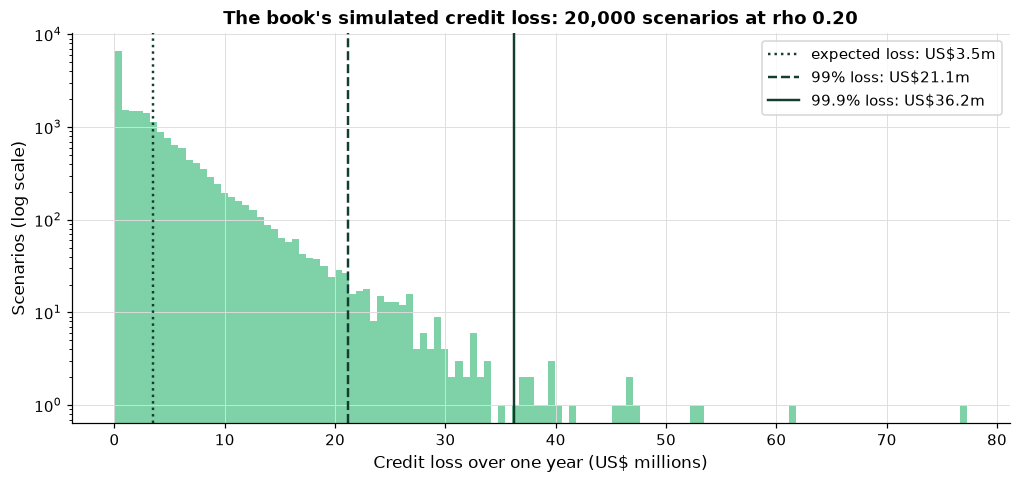

In [39]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.hist(losses / 1e6, bins=120, color=plotkit.GREEN_LIGHT)
ax.set_yscale("log")
for value, label, style in [(losses.mean(), "expected loss", ":"), (credit.loc["99%", "loss (US$)"], "99% loss", "--"),
                            (credit.loc["99.9%", "loss (US$)"], "99.9% loss", "-")]:
    ax.axvline(value / 1e6, color=plotkit.GREEN_DARK, linestyle=style, linewidth=1.6, label=f"{label}: US${value / 1e6:.1f}m")
ax.set_xlabel("Credit loss over one year (US$ millions)")
ax.set_ylabel("Scenarios (log scale)")
ax.set_title("The book's simulated credit loss: 20,000 scenarios at rho 0.20")
ax.legend(loc="upper right")
plt.show()

* How to read it: the y axis is logarithmic, so the long right tail shows. Most scenarios lose little: a few defaults among the high yield bonds. A few lose many times the expected loss, the years when the common factor was bad and the defaults came together. A credit loss distribution is not a bell: it is a heap near zero and a long tail to the right.

Q. Where do the tail losses sit? Average each sector's loss over all scenarios and over the worst 1 percent.

In [40]:
# each bond's loss in each scenario, then the sectors' average losses: over all scenarios, and over the worst 1 percent
per_bond = defaults * lgd * book["market_value"].to_numpy()
worst = losses >= np.quantile(losses, 0.99)
by_bond = pd.DataFrame({"sector": book["sector"], "issuer": book["issuer"],
                        "mean loss": per_bond.mean(axis=0), "mean loss in the worst 1%": per_bond[worst].mean(axis=0)})
sectors = by_bond.groupby("sector")[["mean loss", "mean loss in the worst 1%"]].sum()
sectors["share of the worst 1% (percent)"] = 100 * sectors["mean loss in the worst 1%"] / sectors["mean loss in the worst 1%"].sum()
sectors = sectors.sort_values("mean loss in the worst 1%", ascending=False)
sectors.columns = ["mean loss (US$)", "mean loss in the worst 1% (US$)", "share of the worst 1% (percent)"]
issuers = by_bond.groupby("issuer")["mean loss in the worst 1%"].sum().nlargest(5)
print(f"scenarios in the worst 1%: {int(worst.sum())}")
print("issuers with the largest mean loss in the worst 1% (US$):")
print(issuers.round(0).to_string())

scenarios in the worst 1%: 200
issuers with the largest mean loss in the worst 1% (US$):
issuer
Galvellix Paper       2701589.0
Praxiskan Finance     1962310.0
Xanizal Industrial    1443492.0
Praximer Energy       1432771.0
Nevostrin Water       1337493.0


In [41]:
plotkit.styled(sectors, ["share of the worst 1% (percent)"], "The book by sector: mean loss over all scenarios and over the "
               "worst 1 percent", fmt="{:,.1f}")

,mean loss (US$),mean loss in the worst 1% (US$),share of the worst 1% (percent)
sector,,,
Materials,"637,077.5","5,338,895.3",19.4
Industrials,"640,319.0","4,380,058.8",15.9
Financials,"517,956.3","3,300,213.0",12.0
Consumer,"350,390.0","3,249,472.9",11.8
Telecom,"284,961.5","2,838,161.2",10.3
Energy,"300,749.1","2,352,978.3",8.5
Utilities,"244,438.6","1,701,858.6",6.2
Technology,"272,280.2","1,604,063.3",5.8
Transportation,"102,187.9","1,506,380.4",5.5


* Materials carries the largest share of the worst 1 percent of scenarios, 19.4 percent. A sector's share of the tail follows its high yield bonds: in a bad scenario they are the ones closest to their threshold. The issuer with the largest mean loss in the worst scenarios is Galvellix Paper, an invented issuer.
* The worst 1 percent is 200 scenarios: a small sample, so these shares move a little with the seed.

Q. Sweep rho for the book. What does the 99.9 percent loss do?

In [42]:
# the same book at four correlations: one stream each, the same 20,000 scenarios per correlation
book_rows = []
for rho, stream in zip([0.0, 0.1, 0.2, 0.3], np.random.default_rng(SEED).spawn(4)):
    hits = riskkit.one_factor_defaults(book["pd"].to_numpy(), rho, N_SIMS, stream)
    sweep_losses = riskkit.loss_distribution(book, hits, stream.beta(LGD_A, LGD_B, hits.shape))
    var_999, es_999 = riskkit.var_es(-sweep_losses, 0.999)
    book_rows.append({"rho": rho, "mean loss (US$)": sweep_losses.mean(), "99.9% loss (US$)": var_999,
                      "99.9% expected shortfall (US$)": es_999})
book_sweep = pd.DataFrame(book_rows).set_index("rho")
print(book_sweep.round(0).to_string())

     mean loss (US$)  99.9% loss (US$)  99.9% expected shortfall (US$)
rho                                                                   
0.0        3474452.0        14377673.0                      15648589.0
0.1        3514134.0        24524282.0                      28311377.0
0.2        3525053.0        35672201.0                      44623175.0
0.3        3458822.0        49832686.0                      59633815.0


In [43]:
plotkit.styled(book_sweep, ["99.9% loss (US$)"], "The book at four asset correlations: the mean loss and the 99.9 percent "
               "loss over one year, 20,000 scenarios each", fmt="{:,.0f}")

,mean loss (US$),99.9% loss (US$),99.9% expected shortfall (US$)
rho,,,
0,"3,474,452","14,377,673","15,648,589"
0.1,"3,514,134","24,524,282","28,311,377"
0.2,"3,525,053","35,672,201","44,623,175"
0.3,"3,458,822","49,832,686","59,633,815"


* The mean loss barely moves; the 99.9 percent loss goes from US$14.38m at rho 0 to US$49.83m at rho 0.3. The correlation is an input the data in this course cannot pin down well, and the tail of the loss distribution depends on it more than on anything else. That is the setting to sweep first.

In [44]:
settings = pd.DataFrame([
    ("pd", "the fitted rate of each bond's notch", "each bond's default chance a year", "section 3.1"),
    ("rho", "0.20, an input chosen for the lesson", "how often bonds default together", "one_factor_defaults"),
    ("n_sims", "20,000", "how many scenarios; the 99.9% loss rests on the worst 20", "one_factor_defaults"),
    ("lgd", "beta with a = 6, b = 4: mean 0.6", "the share of value lost in a default", "rng.beta(a, b, size)"),
    ("seed", "SEED = 42", "which scenarios are drawn", "default_rng(SEED)"),
], columns=["setting", "today's choice", "what it controls", "where it is set"]).set_index("setting")
plotkit.styled(settings, [], "The settings of the book's credit loss simulation")

,today's choice,what it controls,where it is set
setting,,,
pd,the fitted rate of each bond's notch,each bond's default chance a year,section 3.1
rho,"0.20, an input chosen for the lesson",how often bonds default together,one_factor_defaults
n_sims,"20,000",how many scenarios; the 99.9% loss rests on the worst 20,one_factor_defaults
lgd,"beta with a = 6, b = 4: mean 0.6",the share of value lost in a default,"rng.beta(a, b, size)"
seed,SEED = 42,which scenarios are drawn,default_rng(SEED)


## 3.6 Correlated Factors and Cholesky

**How it works.** One common factor makes every pair of bonds equally correlated. With two sectors, each with its own factor, the factors need a correlation of their own. Independent normal draws get a correlation matrix C by multiplying them by its **Cholesky factor** L, the lower-triangular matrix with L times its transpose equal to C. Only a true correlation matrix has one: every eigenvalue must be above 0 (positive definite). A matrix whose correlations were typed in one pair at a time can break that, because three correlations can contradict each other. The setting is the matrix. What comes out is L, or an error.

Q. Factor a two-sector correlation matrix, and check the draws it makes.

In [45]:
# two sector factors whose correlation is 0.5, an input chosen for the lesson
corr_two = np.array([[1.0, 0.5],
                     [0.5, 1.0]])
L = np.linalg.cholesky(corr_two)
print(f"Cholesky factor L:\n{L.round(4)}")
print(f"L times its transpose gives the matrix back: {np.allclose(L @ L.T, corr_two)}")

# independent normal draws times L transposed come out with the correlation of the matrix
draws = np.random.default_rng(SEED).standard_normal((100_000, 2)) @ L.T
print(f"correlation of the two drawn factors: {np.corrcoef(draws.T)[0, 1]:.4f}")

Cholesky factor L:
[[1.    0.   ]
 [0.5   0.866]]
L times its transpose gives the matrix back: True
correlation of the two drawn factors: 0.4957


* L times its transpose gives the matrix back, and the drawn factors have a correlation of 0.4957: the 0.5 asked for, within sampling noise. Excel has no Cholesky function; the factor of a 2 by 2 matrix can be typed by hand, and a larger one is a job for code.

Q. Now a 3 by 3 matrix typed one pair at a time. Can it be factored?

In [46]:
# three correlations typed by hand: A and B move together, A and C move apart, and B and C move together
corr_bad = np.array([[1.0, 0.9, -0.6],
                     [0.9, 1.0, 0.4],
                     [-0.6, 0.4, 1.0]])
# a correlation matrix has no negative eigenvalue; this one has one
print(f"eigenvalues: {np.linalg.eigvalsh(corr_bad).round(4).tolist()}")
try:
    np.linalg.cholesky(corr_bad)
except np.linalg.LinAlgError as error:
    # numpy's own message, raised from this cell so the traceback stays short
    raise ValueError(f"Cholesky refused the matrix: {error}") from None

eigenvalues: [-0.2903, 1.3598, 1.9304]


ValueError: Cholesky refused the matrix: Matrix is not positive definite

* No. A and B move together at 0.9, A and C apart at -0.6, so B and C cannot also move together at 0.4: no three variables have those three correlations at once. The smallest eigenvalue, -0.2903, is below zero, and `np.linalg.cholesky` refuses with `LinAlgError`, whose message the cell passes on. A simulation that silently ran on such a matrix would draw factors that cannot exist; the error is the check doing its job.

## A Story: The Formula in the Basel Rules

In July 2005 the Basel Committee on Banking Supervision published "An Explanatory Note on the Basel II IRB Risk Weight Functions". It explains where the capital formula for a bank's loans in the IRB approach of Basel II comes from. Default, it says, follows Merton's 1974 model: a borrower defaults when the value of its assets falls below what it owes. And "With a view on Merton's and Vasicek's ground work, the Basel Committee decided to adopt the assumptions of a normal distribution for the systematic and idiosyncratic risk factors": the common factor and the own factor of section 3.3.

The capital formula holds today's `vasicek_quantile` inside it: the normal distribution applied to (1 - R) to the power -0.5 times the inverse normal of PD, plus (R / (1 - R)) to the power 0.5 times the inverse normal of 0.999, with a "Confidence Level of 99.9%". For corporate exposures the note sets the correlation R between two limits, 12 and 24 percent, and says "Asset correlations decrease with increasing PDs."

The point for a desk: the formula of section 3.4 is not only a classroom check. It is written into the rules banks hold capital by, with the correlation as a supervisory setting, which is why section 3.5 sweeps it.

Source: Basel Committee on Banking Supervision, "An Explanatory Note on the Basel II IRB Risk Weight Functions", July 2005, pages 5, 6, 12, and 13, https://www.bis.org/bcbs/irbriskweight.htm . The note cites O. Vasicek, "Loan portfolio value", *Risk*, December 2002, pages 160 to 162, and R. C. Merton, "On the pricing of corporate debt: The risk structure of interest rates", *Journal of Finance* 29, 1974, pages 449 to 470.

## Excel Side by Side

Excel counts default rates with `AVERAGEIFS`, evaluates the logistic fit with `EXP`, and has the Vasicek formula in one cell. Every formula below was typed into Excel by script (Excel 16.0 build 20430, 2026-10-24). The check pasted the 18,503 development firm-years' buckets and defaults into A2:B18504, the book's default probabilities and market values into D2:E201, and 1,000 uniform draws into G2:G1001.

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| BB default rate | `rates.loc["BB", ...]` | `=AVERAGEIFS(B2:B18504,A2:A18504,"BB")` | 0.012447 |
| The fitted rate of a BB (score 12) | `logit.predict(...)` | `=1/(1+EXP(-($J$1+$J$2*12)))` | 0.011119 |
| The book's expected loss | `(book["pd"] * 0.6 * book["market_value"]).sum()` | `=SUMPRODUCT(D2:D201,E2:E201)*0.6` | US$3,482,412 |
| 10 or more of 100 independent defaults | `binom.sf(9, 100, 0.02)` | `=1-BINOM.DIST(9,100,0.02,TRUE)` | 0.000034 |
| The Vasicek 99.9% default rate | `riskkit.vasicek_quantile(0.02, 0.2, 0.999)` | `=NORM.S.DIST((NORM.S.INV(0.02)+SQRT(0.2)*NORM.S.INV(0.999))/SQRT(1-0.2),TRUE)` | 0.226313 |
| A beta LGD from a uniform | `rng.beta(6, 4)` draws its own way | `=BETA.INV(G2,6,4)` | equal to scipy's `beta.ppf` within 1e-9 |

**Counting.** `AVERAGEIFS(B:B,A:A,"BB")` averages the 0s and 1s of the BB firm-years: that average is the default rate, the same as defaults over firm-years. `COUNTIFS` would give the two counts separately.

**The logistic fit.** Excel has no logistic regression; Solver can fit one by maximising the log-likelihood (Course 6 did that). Given the coefficients, the fitted rate is `1/(1+EXP(-(a+b*score)))`, which is what `logit.predict` computes.

**Vasicek in one cell.** `NORM.S.DIST(...,TRUE)` is N and `NORM.S.INV` is N^-1, so the formula of section 3.4 is one line. `1-BINOM.DIST(9,100,0.02,TRUE)` is the exact chance of 10 or more independent defaults, the rho 0 panel of section 3.3; with rho above 0 there is no such formula for a small group, and the simulation is the answer. `BETA.INV(RAND(),6,4)` draws an LGD the way `NORM.S.INV(RAND())` drew a normal on day 1. Excel has no Cholesky function (section 3.6).

In [47]:
# Excel's results, from the course's Excel check, beside Python's
from scipy.stats import binom
excel_side = pd.DataFrame({
    "Excel": [0.012446518864255154, 0.011119235076246589, 3482412.334772052, 3.441680604310271e-05, 0.2263128071558015],
    "Python": [rates.loc["BB", "default rate (percent a year)"] / 100, notches.loc["BB", "fitted (percent a year)"] / 100,
               expected_loss, binom.sf(9, 100, 0.02), riskkit.vasicek_quantile(0.02, 0.2, 0.999)],
}, index=pd.Index(["BB default rate", "fitted rate of a BB", "the book's expected loss (US$)",
                    "10 or more of 100 independent defaults", "Vasicek 99.9% default rate"], name="Check"))
excel_side["equal within 1e-6"] = (excel_side["Excel"] - excel_side["Python"]).abs() < 1e-6
plotkit.styled(excel_side, [], "Excel beside Python on the cohort, the book, and the formulas", fmt="{:,.6f}")

,Excel,Python,equal within 1e-6
Check,,,
BB default rate,0.012447,0.012447,True
fitted rate of a BB,0.011119,0.011119,True
the book's expected loss (US$),"3,482,412.334772","3,482,412.334772",True
10 or more of 100 independent defaults,0.000034,0.000034,True
Vasicek 99.9% default rate,0.226313,0.226313,True


* Every value is equal within 1e-6. The exact chance of 10 or more independent defaults is 0.000034, about 1.7 in 50,000: section 3.3's simulation of 50,000 scenarios saw none.

## Save the Day with Git

Today's Git step looks before it commits. `git add` puts files in the staging area; `git diff --cached --stat` lists exactly what the next commit will hold, so nothing goes in by accident.

Q. Start a repository in the work folder, and tell Git which files never to track.

In [48]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [49]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5c_03_nb648h7n and nowhere else


In [50]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


Q. Stage the code, check what is staged, then commit.

In [51]:
# --cached compares the staging area with the last commit; --stat lists files and line counts
!git -C "{work}" add .gitignore mlkit.py riskkit.py test_riskkit.py
!git -C "{work}" diff --cached --stat

 .gitignore      |   3 +
 mlkit.py        | 568 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 riskkit.py      | 219 ++++++++++++++++++++++
 test_riskkit.py | 171 +++++++++++++++++
 4 files changed, 961 insertions(+)


In [52]:
!git -C "{work}" commit -q -m "Day 3: riskkit with one_factor_defaults, vasicek_quantile, and loss_distribution"
!git -C "{work}" log --oneline

465fb5a Day 3: riskkit with one_factor_defaults, vasicek_quantile, and loss_distribution

* The staged list held the four code files and nothing else: the cohort, the book, and `plotkit.py` stay out.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and activate the course's environment.

```powershell
Set-Location "$HOME\projects\python-fixed-income"
.\.venv\Scripts\Activate.ps1
Set-Location "$HOME\projects\my_bondmath"
```

**Step 2.** Open `riskkit.py` and paste the code of today's three `riskkit.py` cells (sections 3.3, 3.4, and 3.5) at the end, without their first lines. Do the same for the three `test_riskkit.py` cells in `test_riskkit.py`. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_riskkit.py
```

The last line says `18 passed`.

**Step 4.** Commit.

```powershell
git add riskkit.py test_riskkit.py
git commit -m "Day 3: riskkit with one_factor_defaults, vasicek_quantile, and loss_distribution"
```

## You Can Now

* Count default rates from firm-years, and say why a bucket with no default does not have a zero chance.
* Fill the low-default buckets with a pooled logistic fit, and say what its straight line assumes.
* Show that defaults cluster: yearly counts that vary 2.2 times as much as independence allows.
* Simulate defaults that move together through one common factor (`one_factor_defaults`), and say what rho does to the mean and to the tail.
* Check a simulation against the Vasicek formula (`vasicek_quantile`).
* Simulate a book's credit loss (`loss_distribution`), read its 99.9 percent loss and expected shortfall, and find the sectors in its tail.
* Factor a correlation matrix with Cholesky, and read the error when it is not one.

Next, day 4: survival curves and Kaplan-Meier, where the question becomes when a firm defaults, not whether.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the cohort's development years, fits the pooled logistic regression of section 3.1, gives the book its default probabilities, and defines `check`, a small function that marks your answers.

In [53]:
import statsmodels.api as sm
from scipy.stats import norm

# the cohort's development years, the pooled logistic fit, and the book's default probabilities, as in section 3.1
cohort = pd.read_csv("course5c_cohort.csv")
ratings = pd.read_csv("ratings.csv").set_index("rating")
development = cohort[cohort["study_year"] <= 14].copy()
X = sm.add_constant(development[["rating_score"]].astype(float))
logit = sm.Logit(development["default"], X).fit(disp=0)
book = pd.read_csv("holdings.csv")
book["rating_score"] = book["rating"].map(ratings["score"]).astype(float)
book["pd"] = logit.predict(sm.add_constant(book[["rating_score"]]))
print(f"{len(development):,} development firm-years; {len(book)} bonds with a fitted default probability")


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

18,503 development firm-years; 200 bonds with a fitted default probability


### Exercise 1

Q. With the Vasicek formula, what default rate does a large group of alike bonds with a 1 percent default chance and an asset correlation of 0.12 exceed only once in a thousand years? Store it in **ex1_rate**.

In [54]:
ex1_rate = ...

In [55]:
check("Exercise 1 Vasicek default rate", ex1_rate, 0.09032583132606531)

Exercise 1 Vasicek default rate: not attempted yet


### Exercise 2

Q. For 100 alike bonds at a 2 percent default chance and rho 0.3, simulate 50,000 scenarios with `riskkit.one_factor_defaults` and a generator from `SEED`. What share of scenarios has 10 or more defaults? Store it in **ex2_share**.

In [56]:
ex2_share = ...

In [57]:
check("Exercise 2 share with 10 or more defaults", ex2_share, 0.0458)

Exercise 2 share with 10 or more defaults: not attempted yet


### Exercise 3

Q. Add a function to your module. `vasicek_cdf(x, pd, rho)` returns the chance that a large group's default rate is at most x: N((sqrt(1 - rho) N^-1(x) - N^-1(pd)) / sqrt(rho)). It refuses an input outside (0, 1) with `ValueError`. Write the docstring first. Add `test_vasicek_cdf_inverts_the_quantile`, which checks that `vasicek_cdf(vasicek_quantile(0.02, 0.2, q), 0.02, 0.2)` gives q back for q = 0.5, 0.9, and 0.999. Run pytest, reload the module, and store the chance that the default rate of a large group at 2 percent and rho 0.2 is above 10 percent in **ex3_above_10**.

Write the function in the cell that starts with `%%writefile -a riskkit.py` and the test in the one that starts with `%%writefile -a test_riskkit.py`, and run each of those cells once.

In [58]:
%%writefile -a riskkit.py


# Exercise 3: write vasicek_cdf(x, pd, rho) below this line

Appending to riskkit.py


In [59]:
%%writefile -a test_riskkit.py


# Exercise 3: write test_vasicek_cdf_inverts_the_quantile() below this line

Appending to test_riskkit.py


In [60]:
# run pytest, reload the module, then use your function
ex3_above_10 = ...

In [61]:
check("Exercise 3 chance of a default rate above 10 percent", ex3_above_10, 0.021217992460147328)

Exercise 3 chance of a default rate above 10 percent: not attempted yet


### Exercise 4

Q. Swap the normal model for a **Student's t copula** with 4 degrees of freedom. In each scenario draw the common and own factors as before, plus one chi-squared draw W with 4 degrees of freedom shared by every bond; divide the asset values by sqrt(W / 4); and use the t quantile of the default chance as the threshold (`scipy.stats.t.ppf(0.02, 4)`), so each bond still defaults 2 percent of the time. For 100 alike bonds at rho 0.2, 50,000 scenarios, draw in this order from one generator from `SEED`: the common factors (50,000 by 1), the own factors (50,000 by 100), then W (50,000 by 1). Store the share of scenarios with 10 or more defaults in **ex4_share**, and compare it with the normal model's at rho 0.2.

In [62]:
ex4_share = ...

In [63]:
check("Exercise 4 t copula share with 10 or more defaults", ex4_share, 0.06296)

Exercise 4 t copula share with 10 or more defaults: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that simulates correlated defaults, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Defaults of a group of bonds that move together through one common factor.

    pd is an array of annual default probabilities, one per bond; rho is the asset correlation. In each scenario
    one common draw Z is shared by every bond, and each bond adds a draw e of its own:
    asset = sqrt(rho) Z + sqrt(1 - rho) e. A bond defaults when its asset is below norm.ppf(pd).
    Returns a boolean array of shape (n_sims, bonds).
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, gives every bond its own default rate, and contains one bug.

In [64]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def correlated_defaults(pd, rho, n_sims, rng):
    """Defaults of a group of bonds that move together through one common factor.

    pd is an array of annual default probabilities, one per bond; rho is the asset correlation. In each scenario
    one common draw Z is shared by every bond, and each bond adds a draw e of its own:
    asset = sqrt(rho) Z + sqrt(1 - rho) e. A bond defaults when its asset is below norm.ppf(pd).
    Returns a boolean array of shape (n_sims, bonds).
    """
    pd = np.asarray(pd, dtype=float)
    common = rng.standard_normal((n_sims, len(pd)))
    own = rng.standard_normal((n_sims, len(pd)))
    assets = np.sqrt(rho) * common + np.sqrt(1 - rho) * own
    return assets < norm.ppf(pd)

Q. Before you run the next cell: with rho 0.3, should a year with 10 or more defaults among 100 bonds at 2 percent be rare or fairly common? What does the function give?

In [65]:
counts = correlated_defaults(np.full(100, 0.02), 0.3, 20_000, np.random.default_rng(SEED)).sum(axis=1)
print(f"mean {counts.mean():.2f}; 10 or more defaults in {np.mean(counts >= 10):.4%} of scenarios")

mean 2.00; 10 or more defaults in 0.0000% of scenarios


Q. Test the function against its docstring before you trust it: the mean count is 2, and with rho 0.3 the count must vary far more than independent defaults would.

In [66]:
# the test, written from the docstring before the code is trusted
counts = correlated_defaults(np.full(100, 0.02), 0.3, 20_000, np.random.default_rng(SEED)).sum(axis=1)
independent_variance = 100 * 0.02 * 0.98
# the mean count is 2 at any rho; with rho 0.3 the count must vary far more than independent defaults would
assert abs(counts.mean() - 2.0) < 0.15, f"mean count {counts.mean():.2f}, not 2"
assert counts.var() > 3 * independent_variance, f"variance {counts.var():.2f}: no more than independent defaults ({independent_variance:.2f})"
print(f"mean count {counts.mean():.2f}, variance {counts.var():.2f} against {independent_variance:.2f} if independent")

AssertionError: variance 1.96: no more than independent defaults (1.96)

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the share of the fixed function's 20,000 scenarios with 10 or more defaults, `float(np.mean(counts >= 10))` after the test, in **ex5_share**.

In [67]:
# fix the function above and run the test again, then store the answer
ex5_share = ...

In [68]:
check("Exercise 5 share with 10 or more defaults, fixed function", ex5_share, 0.0454)

Exercise 5 share with 10 or more defaults, fixed function: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```